In [ ]:
# ===================== 1. Imports & Setup =====================
!pip install -q datasets

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import math
import time
from datasets import load_dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if not torch.cuda.is_available():
    raise RuntimeError("GPU not available! In Colab: Runtime → Change runtime type → T4 GPU")
print(f"GPU: {torch.cuda.get_device_name(0)}")

GPU: Tesla T4


In [ ]:
# ===================== 2. Tokenizer =====================
class CharTokenizer:
    def __init__(self, text):
        chars = sorted(list(set(text)))
        self.stoi = {ch: i for i, ch in enumerate(chars)}
        self.itos = {i: ch for i, ch in enumerate(chars)}
        self.vocab_size = len(chars)

    def encode(self, s):
        return [self.stoi[ch] for ch in s if ch in self.stoi]

    def decode(self, ids):
        return ''.join(self.itos[i] for i in ids)

dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="train")
raw_text = "\n".join([t for t in dataset["text"] if t])
tokenizer = CharTokenizer(raw_text)
vocab_size = tokenizer.vocab_size
print(f"Vocab size: {vocab_size}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…):   0%|          | 0.00/733k [00:00<?, ?B/s]

wikitext-2-raw-v1/train-00000-of-00001.p(…):   0%|          | 0.00/6.36M [00:00<?, ?B/s]

wikitext-2-raw-v1/validation-00000-of-00(…):   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Vocab size: 1013


In [ ]:
# ===================== 3. Tiny Dataset & Memory Chunks =====================
SUBSET_TOKENS = 100000
CONTEXT_LEN = 64
CHUNK_LEN = 64

full_ids = torch.tensor(tokenizer.encode(raw_text), dtype=torch.long)[:SUBSET_TOKENS]
num_chunks = len(full_ids) // CHUNK_LEN
memory_chunks = full_ids[:num_chunks * CHUNK_LEN].view(num_chunks, CHUNK_LEN)

class TextDataset(Dataset):
    def __init__(self, data, ctx_len):
        self.data = data
        self.ctx_len = ctx_len

    def __len__(self):
        return len(self.data) - self.ctx_len

    def __getitem__(self, idx):
        return self.data[idx:idx+self.ctx_len], self.data[idx+1:idx+self.ctx_len+1]

split = int(0.9 * len(full_ids))
train_ds = TextDataset(full_ids[:split], CONTEXT_LEN)
test_ds = TextDataset(full_ids[split:], CONTEXT_LEN)

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

print(f"Train batches: {len(train_loader)}, Test batches: {len(test_loader)}")
print(f"Memory chunks: {memory_chunks.shape}")

Train batches: 703, Test batches: 78
Memory chunks: torch.Size([1562, 64])


In [ ]:
# ===================== 4. Causal Self-Attention =====================
class MultiHeadCausalSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", None)

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).reshape(B, T, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        scale = math.sqrt(self.head_dim)
        attn = (q @ k.transpose(-2, -1)) / scale

        if self.mask is None or self.mask.size(-1) != T:
            mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
            self.register_buffer("mask", mask)

        attn = attn + self.mask[:T, :T]
        attn = F.softmax(attn, dim=-1)
        attn = self.dropout(attn)
        out = attn @ v
        return self.out_proj(out.transpose(1, 2).contiguous().reshape(B, T, C))

In [ ]:
# ===================== 5. Decoder Block =====================
class FeedForward(nn.Module):
    def __init__(self, embed_dim, expansion_factor=4, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * expansion_factor),
            nn.GELU(),
            nn.Linear(embed_dim * expansion_factor, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)

class DecoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadCausalSelfAttention(embed_dim, num_heads, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.ff = FeedForward(embed_dim, dropout=dropout)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.self_attn(self.norm1(x))
        x = x + self.ff(self.norm2(x))
        return x

In [ ]:
# ===================== 6. Vanilla Model =====================
class DecoderOnlyTransformer(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_layers, num_heads, block_size, dropout=0.1):
        super().__init__()
        self.token_embed = nn.Embedding(vocab_size, embed_dim)
        self.pos_embed = nn.Embedding(block_size, embed_dim)
        self.blocks = nn.ModuleList([DecoderBlock(embed_dim, num_heads, dropout) for _ in range(num_layers)])
        self.norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)
        self.block_size = block_size

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(0, T, device=idx.device).unsqueeze(0)
        x = self.token_embed(idx) + self.pos_embed(pos)
        for block in self.blocks:
            x = block(x)
        return self.lm_head(self.norm(x))

In [ ]:
# ===================== 7. Train Vanilla (with history) =====================
def train_vanilla(model, loader, epochs, lr=1e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler('cuda')
    model.train()
    history = []
    for ep in range(epochs):
        t0 = time.time()
        total_loss = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.amp.autocast('cuda'):
                logits = model(x)
                loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            total_loss += loss.item()
        avg = total_loss / len(loader)
        history.append(avg)
        print(f"Vanilla Epoch {ep+1}/{epochs} | Loss: {avg:.4f} | {time.time()-t0:.1f}s")
    return model, history

vanilla = DecoderOnlyTransformer(vocab_size, 128, 2, 2, CONTEXT_LEN).to(device)
vanilla, vanilla_loss = train_vanilla(vanilla, train_loader, 200)

Vanilla Epoch 1/200 | Loss: 2.1625 | 8.7s
Vanilla Epoch 2/200 | Loss: 1.4619 | 7.8s
Vanilla Epoch 3/200 | Loss: 1.2280 | 7.5s
Vanilla Epoch 4/200 | Loss: 1.0927 | 7.6s
Vanilla Epoch 5/200 | Loss: 1.0020 | 7.3s
Vanilla Epoch 6/200 | Loss: 0.9367 | 7.4s
Vanilla Epoch 7/200 | Loss: 0.8854 | 7.5s
Vanilla Epoch 8/200 | Loss: 0.8453 | 7.2s
Vanilla Epoch 9/200 | Loss: 0.8128 | 7.5s
Vanilla Epoch 10/200 | Loss: 0.7836 | 7.3s
Vanilla Epoch 11/200 | Loss: 0.7600 | 7.5s
Vanilla Epoch 12/200 | Loss: 0.7392 | 7.6s
Vanilla Epoch 13/200 | Loss: 0.7213 | 7.4s
Vanilla Epoch 14/200 | Loss: 0.7049 | 7.6s
Vanilla Epoch 15/200 | Loss: 0.6912 | 7.4s
Vanilla Epoch 16/200 | Loss: 0.6773 | 7.4s
Vanilla Epoch 17/200 | Loss: 0.6648 | 7.5s
Vanilla Epoch 18/200 | Loss: 0.6540 | 7.2s
Vanilla Epoch 19/200 | Loss: 0.6434 | 7.5s
Vanilla Epoch 20/200 | Loss: 0.6342 | 7.3s
Vanilla Epoch 21/200 | Loss: 0.6264 | 7.4s
Vanilla Epoch 22/200 | Loss: 0.6178 | 7.5s
Vanilla Epoch 23/200 | Loss: 0.6106 | 7.2s
Vanilla Epoch 24/200

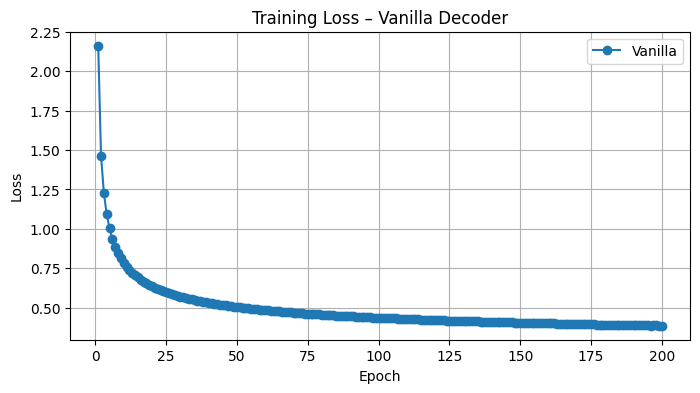

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(range(1, len(vanilla_loss)+1), vanilla_loss, marker='o', label='Vanilla')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss – Vanilla Decoder')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ===================== 8. Memory Bank (corrected) =====================
class MemoryBank:
    def __init__(self, chunks, token_embed, embed_dim):
        self.chunks = chunks.to(device)
        self.token_embed = token_embed
        with torch.no_grad():
            pos = torch.arange(0, self.chunks.size(1), device=device).unsqueeze(0)
            chunk_emb = self.token_embed(self.chunks) + nn.Embedding(self.chunks.size(1), embed_dim).to(device)(pos)
            self.embeddings = chunk_emb.mean(dim=1)

    def retrieve(self, query, k=4):
        query = query / query.norm(dim=-1, keepdim=True)
        sim = query @ (self.embeddings / self.embeddings.norm(dim=-1, keepdim=True)).T
        _, idx = torch.topk(sim, k, dim=-1)
        return self.chunks[idx]

In [ ]:
# ===================== 9. Memory Cross-Attention  =====================
class MemoryCrossAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.kv_proj = nn.Linear(embed_dim, 2 * embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.gate = nn.Sequential(nn.Linear(2*embed_dim, embed_dim), nn.Sigmoid())
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, memory_embeddings):
        B, T, C = x.shape
        K, V = self.kv_proj(memory_embeddings).chunk(2, dim=-1)
        S = K.size(1)
        K = K.view(B, S, self.num_heads, self.head_dim).permute(0,2,1,3)
        V = V.view(B, S, self.num_heads, self.head_dim).permute(0,2,1,3)
        Q = self.q_proj(x).view(B, T, self.num_heads, self.head_dim).permute(0,2,1,3)

        attn = (Q @ K.transpose(-2,-1)) / math.sqrt(self.head_dim)
        attn = F.softmax(attn, dim=-1)
        attn = self.dropout(attn)
        mem_out = (attn @ V).transpose(1,2).contiguous().reshape(B, T, C)
        mem_out = self.out_proj(mem_out)
        gate = self.gate(torch.cat([x, mem_out], dim=-1))
        return gate * mem_out + (1 - gate) * x

In [ ]:
# ===================== 10. TinyRETRO Model (fixed flatten) =====================
class TinyRETRO(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_layers, num_heads, block_size, memory_bank, mem_layer_idx=1):
        super().__init__()
        self.token_embed = nn.Embedding(vocab_size, embed_dim)
        self.pos_embed = nn.Embedding(block_size, embed_dim)
        self.memory_bank = memory_bank
        self.mem_layer_idx = mem_layer_idx

        self.blocks = nn.ModuleList()
        for i in range(num_layers):
            if i == mem_layer_idx:
                self.blocks.append(DecoderBlock(embed_dim, num_heads))
                self.blocks.append(MemoryCrossAttention(embed_dim, num_heads))
            else:
                self.blocks.append(DecoderBlock(embed_dim, num_heads))
        self.norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)
        self.block_size = block_size

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(0, T, device=idx.device).unsqueeze(0)
        x = self.token_embed(idx) + self.pos_embed(pos)

        mem_retrieved = None
        for i, block in enumerate(self.blocks):
            if isinstance(block, MemoryCrossAttention):
                if mem_retrieved is None:
                    query = x.mean(dim=1)
                    mem_tokens = self.memory_bank.retrieve(query, k=4)          # [B, k, CHUNK_LEN]
                    mem_emb = self.token_embed(mem_tokens)                     # [B, k, CHUNK_LEN, C]
                    mem_retrieved = mem_emb.view(B, -1, mem_emb.size(-1))      # flatten to [B, S, C]
                x = block(x, mem_retrieved)
            else:
                x = block(x)
        return self.lm_head(self.norm(x))



In [ ]:
# ===================== 11. Train TinyRETRO =====================
mem_bank = MemoryBank(memory_chunks, nn.Embedding(vocab_size, 128).to(device), 128)
retro = TinyRETRO(vocab_size, 128, 2, 2, CONTEXT_LEN, mem_bank).to(device)

opt = torch.optim.AdamW(retro.parameters(), lr=1e-3)
scaler = torch.amp.GradScaler('cuda')
retro.train()
retro_loss = []
epochs = 200
for ep in range(epochs):
    t0 = time.time()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        with torch.amp.autocast('cuda'):
            logits = retro(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total_loss += loss.item()
    avg = total_loss / len(train_loader)
    retro_loss.append(avg)
    print(f"TinyRETRO Epoch {ep+1}/{epochs} | Loss: {avg:.4f} | {time.time()-t0:.1f}s")

TinyRETRO Epoch 1/200 | Loss: 2.1176 | 11.4s
TinyRETRO Epoch 2/200 | Loss: 1.4269 | 11.3s
TinyRETRO Epoch 3/200 | Loss: 1.2000 | 11.4s
TinyRETRO Epoch 4/200 | Loss: 1.0599 | 11.4s
TinyRETRO Epoch 5/200 | Loss: 0.9615 | 11.3s
TinyRETRO Epoch 6/200 | Loss: 0.8897 | 11.3s
TinyRETRO Epoch 7/200 | Loss: 0.8331 | 11.3s
TinyRETRO Epoch 8/200 | Loss: 0.7878 | 11.3s
TinyRETRO Epoch 9/200 | Loss: 0.7505 | 11.3s
TinyRETRO Epoch 10/200 | Loss: 0.7188 | 11.3s
TinyRETRO Epoch 11/200 | Loss: 0.6898 | 11.3s
TinyRETRO Epoch 12/200 | Loss: 0.6656 | 11.3s
TinyRETRO Epoch 13/200 | Loss: 0.6432 | 11.3s
TinyRETRO Epoch 14/200 | Loss: 0.6231 | 11.4s
TinyRETRO Epoch 15/200 | Loss: 0.6057 | 11.3s
TinyRETRO Epoch 16/200 | Loss: 0.5894 | 11.3s
TinyRETRO Epoch 17/200 | Loss: 0.5753 | 11.3s
TinyRETRO Epoch 18/200 | Loss: 0.5618 | 11.3s
TinyRETRO Epoch 19/200 | Loss: 0.5484 | 11.3s
TinyRETRO Epoch 20/200 | Loss: 0.5377 | 11.3s
TinyRETRO Epoch 21/200 | Loss: 0.5273 | 11.3s
TinyRETRO Epoch 22/200 | Loss: 0.5174 | 11.

In [ ]:
# ===================== Fix retro.forward (patch) =====================
def fixed_forward(self, idx):
    B, T = idx.shape
    pos = torch.arange(0, T, device=idx.device).unsqueeze(0)
    x = self.token_embed(idx) + self.pos_embed(pos)

    mem_retrieved = None
    for block in self.blocks:
        # Check class name instead of isinstance (handles re-definitions)
        if block.__class__.__name__ == 'MemoryCrossAttention':
            if mem_retrieved is None:
                query = x.mean(dim=1)
                mem_tokens = self.memory_bank.retrieve(query, k=4)
                mem_emb = self.token_embed(mem_tokens)
                mem_retrieved = mem_emb.view(B, -1, mem_emb.size(-1))
            x = block(x, mem_retrieved)
        else:
            x = block(x)
    return self.lm_head(self.norm(x))

retro.forward = fixed_forward.__get__(retro, TinyRETRO)
print("Forward method patched. Perplexity and ablation will now work.")

Forward method patched. Perplexity and ablation will now work.


In [ ]:
# ===================== 12. Perplexity Comparison =====================
@torch.no_grad()
def perplexity(model, loader):
    model.eval()
    total_loss, total_tokens = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1), reduction='sum')
        total_loss += loss.item()
        total_tokens += y.numel()
    return math.exp(total_loss / total_tokens)

vanilla_ppl = perplexity(vanilla, test_loader)
retro_ppl = perplexity(retro, test_loader)
print(f"Vanilla perplexity: {vanilla_ppl:.2f}")
print(f"TinyRETRO perplexity: {retro_ppl:.2f}")

Vanilla perplexity: 95.59
TinyRETRO perplexity: 105.47


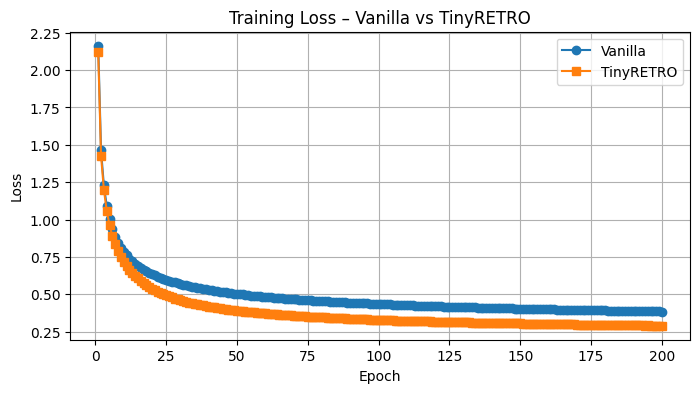

In [ ]:
# ===================== 13. Loss Curve Comparison =====================
plt.figure(figsize=(8,4))
plt.plot(range(1, len(vanilla_loss)+1), vanilla_loss, marker='o', label='Vanilla')
plt.plot(range(1, len(retro_loss)+1), retro_loss, marker='s', label='TinyRETRO')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss – Vanilla vs TinyRETRO')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ===================== 14. Ablation (disable memory) =====================
class ZeroGate(nn.Module):
    def forward(self, x):
        return torch.zeros_like(x[:, :, :x.size(-1)//2])  # gate expects [B,T,2C] -> output [B,T,C]

original_gates = {}
for i, block in enumerate(retro.blocks):
    if isinstance(block, MemoryCrossAttention):
        original_gates[i] = block.gate
        block.gate = ZeroGate()

retro_ppl_no_mem = perplexity(retro, test_loader)
print(f"TinyRETRO (memory off) perplexity: {retro_ppl_no_mem:.2f}")

# Restore gates
for i, block in enumerate(retro.blocks):
    if i in original_gates:
        block.gate = original_gates[i]

TinyRETRO (memory off) perplexity: 105.47


In [ ]:
# ===================== 15. Generation Demo =====================
@torch.no_grad()
def generate(model, prompt, max_new=100, temperature=0.8):
    model.eval()
    ids = torch.tensor(tokenizer.encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    for _ in range(max_new):
        if ids.size(1) > CONTEXT_LEN:
            ids = ids[:, -CONTEXT_LEN:]
        logits = model(ids)[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probs, 1)
        ids = torch.cat([ids, next_id], dim=1)
    return tokenizer.decode(ids[0].tolist())

print("===== Vanilla Generation =====")
print(generate(vanilla, "The history of", max_new=120))
print("\n===== TinyRETRO Generation =====")
print(generate(retro, "The history of", max_new=120))

===== Vanilla Generation =====
 the building , while the tower served as a hoist to move munitio

===== TinyRETRO Generation =====
 the building or camped in the park , which had also become a pos


In [ ]:
s